#Phase 1: Algorithms

In [ ]:
#get helper functions
%run '/content/drive/MyDrive/Colab Notebooks/RCC_Beam_Optimization/helper_functions.ipynb'

In [ ]:
!pip install deap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.6/135.6 kB 3.8 MB/s eta 0:00:00


In [ ]:
!pip install pyswarm

  Preparing metadata (setup.py) ... done
  Created wheel for pyswarm: filename=pyswarm-0.6-py3-none-any.whl size=4463 sha256=17339d580221b72aa0a6bdb1d10d915936ebc794b771e14f1fb97087998b39e0
  Stored in directory: /root/.cache/pip/wheels/bb/4f/ec/8970b83323e16aa95034da175454843947376614d6d5e9627f
Successfully built pyswarm


In [ ]:
from deap import base, creator, tools, algorithms
from scipy.optimize import differential_evolution
from pyswarm import pso
from scipy.optimize import dual_annealing

In [ ]:
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#get helper functions
%run '/content/drive/MyDrive/Colab Notebooks/RCC_Beam_Optimization/helper_functions.ipynb'


In [ ]:
param_ranges

{'b': (200.0, 500.0), 'd': (300.0, 1500.0), 'Ast': (200.0, 10000.0)}

In [ ]:
# ================================
# Phase 1: Updated Optimizers
# ================================

def clip_design(b, d, Ast, param_ranges):
    b = max(min(b, param_ranges['b'][1]), param_ranges['b'][0])
    d = max(min(d, param_ranges['d'][1]), param_ranges['d'][0])
    Ast = max(min(Ast, param_ranges['Ast'][1]), param_ranges['Ast'][0])
    # if b / d < 0.3:
    #     b = 0.3001 * d
    #     # Re-clip b in case it exceeds max after adjustment
    #     b = max(min(b, param_ranges['b'][1]), param_ranges['b'][0])
    return b, d, Ast

def run_ga(fck, fy, Mu, param_ranges, generations=50, population_size=100):
    if "FitnessMax" not in creator.__dict__:
        creator.create("FitnessMax", base.Fitness, weights=(1.0,))
    if "Individual" not in creator.__dict__:
        creator.create("Individual", list, fitness=creator.FitnessMax)

    toolbox = base.Toolbox()
    toolbox.register("attr_b", np.random.randint, *param_ranges['b'])
    toolbox.register("attr_d", np.random.randint, *param_ranges['d'])
    toolbox.register("attr_Ast", np.random.randint, *param_ranges['Ast'])
    toolbox.register("individual", tools.initCycle, creator.Individual,
                     (toolbox.attr_b, toolbox.attr_d, toolbox.attr_Ast), n=1)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)

    def evaluate(ind):
        b, d, Ast = ind
        return get_reward(b, d, Ast, fck, fy, Mu),

    toolbox.register("evaluate", evaluate)
    toolbox.register("mate", tools.cxBlend, alpha=0.5)
    toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=50, indpb=0.2)
    toolbox.register("select", tools.selTournament, tournsize=3)

    def feasibility(ind):
        return (1,) if is_valid_design(*ind, fck, fy, Mu) else (0,)

    toolbox.decorate("evaluate", tools.DeltaPenalty(feasibility, 0.0))

    pop = toolbox.population(n=population_size)
    hof = tools.HallOfFame(1)
    algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=generations,
                        halloffame=hof, verbose=False)

    return clip_design(*hof[0], param_ranges)

def run_de(fck, fy, Mu, param_ranges, max_iter=100, pop_size=15):
    def objective(x):
        b, d, Ast = x
        if not is_valid_design(b, d, Ast, fck, fy, Mu): return 1e6
        return -get_reward(b, d, Ast, fck, fy, Mu)

    bounds = [param_ranges['b'], param_ranges['d'], param_ranges['Ast']]

    result = differential_evolution(objective, bounds, maxiter=max_iter, popsize=pop_size)
    return clip_design(*result.x, param_ranges)

def run_pso(fck, fy, Mu, param_ranges, swarmsize=30, maxiter=100):
    from pyswarm import pso

    def objective(x):
        b, d, Ast = x
        if not is_valid_design(b, d, Ast, fck, fy, Mu): return 1e6
        return -get_reward(b, d, Ast, fck, fy, Mu)

    lb = [param_ranges[k][0] for k in ['b', 'd', 'Ast']]
    ub = [param_ranges[k][1] for k in ['b', 'd', 'Ast']]

    xopt, _ = pso(objective, lb, ub, swarmsize=swarmsize, maxiter=maxiter)
    return clip_design(*xopt, param_ranges)

def run_sa(fck, fy, Mu, param_ranges, max_iter=1000):
    from scipy.optimize import dual_annealing

    def objective(x):
        b, d, Ast = x
        if not is_valid_design(b, d, Ast, fck, fy, Mu): return 1e6
        return -get_reward(b, d, Ast, fck, fy, Mu)

    bounds = [param_ranges[k] for k in ['b', 'd', 'Ast']]
    result = dual_annealing(objective, bounds, maxiter=max_iter)
    return clip_design(*result.x, param_ranges)

#Phase 2: Dataset builder

In [ ]:
# ================================
# Phase 2: Dataset Collector
# ================================

def collect_best_by_ensemble(algorithms, fck_list, fy_list, Mu_list, param_ranges, filename):
    import itertools, pandas as pd

    rows = []

    for fck, fy, Mu in itertools.product(fck_list, fy_list, Mu_list):
        best_reward = -1e9
        best_row = None

        for algo in algorithms:
            try:
                if algo == "GA":
                    b, d, Ast = run_ga(fck, fy, Mu, param_ranges)
                elif algo == "DE":
                    b, d, Ast = run_de(fck, fy, Mu, param_ranges)
                elif algo == "PSO":
                    b, d, Ast = run_pso(fck, fy, Mu, param_ranges)
                elif algo == "SA":
                    b, d, Ast = run_sa(fck, fy, Mu, param_ranges)
                else:
                    continue

                reward = get_reward(b, d, Ast, fck, fy, Mu)
                if is_valid_design(b, d, Ast, fck, fy, Mu) and reward > best_reward:
                    best_reward = reward
                    b=math.ceil(b)
                    d=math.ceil(d)
                    Ast=math.ceil(Ast*10)/10
                    if b < 0.3*d:
                        b = math.ceil(0.3*d)
                    best_row = {
                        "fck": fck,
                        "fy": fy,
                        "Mu": Mu,
                        "b": b,
                        "d": d,
                        "Ast": Ast,
                        "algorithm": algo,

                    }

            except Exception as e:
                print(f"{algo} failed for fck={fck}, fy={fy}, Mu={Mu}: {e}")

        if best_row:
            rows.append(best_row)

    df = pd.DataFrame(rows)
    df["is_valid"] = df.apply(lambda row: is_valid_design(row.b, row.d, row.Ast, row.fck, row.fy, row.Mu), axis=1)
    df["cost"] = df.apply(lambda row: get_cost(row.b, row.d, row.Ast), axis=1)
    df["MOR"] = df.apply(lambda row: calculate_moment_capacity(row.b, row.d, row.Ast, row.fck, row.fy)[0], axis=1).round(4)
    df["Mul"] = df.apply(lambda row: calculate_moment_capacity(row.b, row.d, row.Ast, row.fck, row.fy)[1], axis=1).round(4)
    df["utilization"] = (df["Mu"] / df["MOR"]).round(4)
    df["rho"] = (df["Ast"] / (df["b"] * df["d"])).round(4)
    df["bd_ratio"] = (df["b"] / df["d"]).round(3)

    df.to_csv(filename, index=False)
    print(f"Saved {len(df)} records to {filename}")


In [ ]:
fck_list = list(range(30, 41, 5))
fy_list=[500, 550]
Mu_list = list(range(1050, 1201, 25))

In [ ]:
len(fck_list) * len(fy_list) * len(Mu_list)

42

In [ ]:
collect_best_by_ensemble(
    algorithms=["GA", "DE", "PSO", "SA"],
    fck_list=fck_list,
    fy_list=fy_list,
    Mu_list=Mu_list,

    param_ranges=param_ranges,
    filename="new_ensemble_best_designs.csv"
)


Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping sea

#Exploratory data analysis (EDA)

In [ ]:
# Load dataset
df = pd.read_csv("new_ensemble_best_designs.csv")
df.head()

,fck,fy,Mu,b,d,Ast,algorithm,is_valid,cost,MOR,Mul,utilization,rho,bd_ratio
0,30,500,1050,288,959,3109.9,DE,True,7560.66,1052.577,1057.027,0.9976,0.0113,0.300
1,30,500,1075,291,966,3156.2,DE,True,7685.25,1076.759,1083.682,0.9984,0.0112,0.301
2,30,500,1100,293,973,3208.7,DE,True,7802.70,1101.981,1106.997,0.9982,0.0113,0.301
3,30,500,1125,296,986,3221.2,DE,True,7917.94,1126.104,1148.418,0.9990,0.0110,0.300
4,30,500,1150,298,988,3302.0,DE,True,8045.26,1152.456,1160.868,0.9979,0.0112,0.302


In [ ]:
df.describe()

,fck,fy,Mu,b,d,Ast,cost,MOR,Mul,utilization,rho,bd_ratio
count,42.000000,42.000000,42.000000,42.000000,42.000000,42.00000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000
mean,35.000000,525.000000,1125.000000,283.380952,942.166667,3213.67381,7542.879762,1126.798786,1149.480643,0.998414,0.012124,0.300810
std,4.131969,25.303041,50.606083,11.320071,37.254508,226.88292,332.505601,50.709257,57.404574,0.000795,0.001478,0.000552
min,30.000000,500.000000,1050.000000,265.000000,882.000000,2788.40000,6852.840000,1050.591000,1052.555000,0.995300,0.009800,0.300000
25%,30.000000,500.000000,1075.000000,275.250000,916.250000,3033.82500,7300.007500,1076.798500,1106.302500,0.998100,0.011200,0.300250
50%,35.000000,525.000000,1125.000000,282.000000,936.500000,3218.50000,7539.115000,1126.347500,1151.145000,0.998450,0.012150,0.301000
75%,40.000000,550.000000,1175.000000,292.500000,971.750000,3355.37500,7784.050000,1176.254750,1187.410500,0.999000,0.013175,0.301000
max,40.000000,550.000000,1200.000000,304.000000,1009.000000,3693.90000,8276.490000,1202.439000,1262.945000,0.999500,0.014800,0.302000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   fck          42 non-null     int64  
 1   fy           42 non-null     int64  
 2   Mu           42 non-null     int64  
 3   b            42 non-null     int64  
 4   d            42 non-null     int64  
 5   Ast          42 non-null     float64
 6   algorithm    42 non-null     object 
 7   is_valid     42 non-null     bool   
 8   cost         42 non-null     float64
 9   MOR          42 non-null     float64
 10  Mul          42 non-null     float64
 11  utilization  42 non-null     float64
 12  rho          42 non-null     float64
 13  bd_ratio     42 non-null     float64
dtypes: bool(1), float64(7), int64(5), object(1)
memory usage: 4.4+ KB


In [ ]:
duplicates = df.duplicated().sum()
print(duplicates)

0


In [ ]:
print("🧹 Missing Values:")
print(df.isnull().sum())

🧹 Missing Values:
fck            0
fy             0
Mu             0
b              0
d              0
Ast            0
algorithm      0
is_valid       0
cost           0
MOR            0
Mul            0
utilization    0
rho            0
bd_ratio       0
dtype: int64


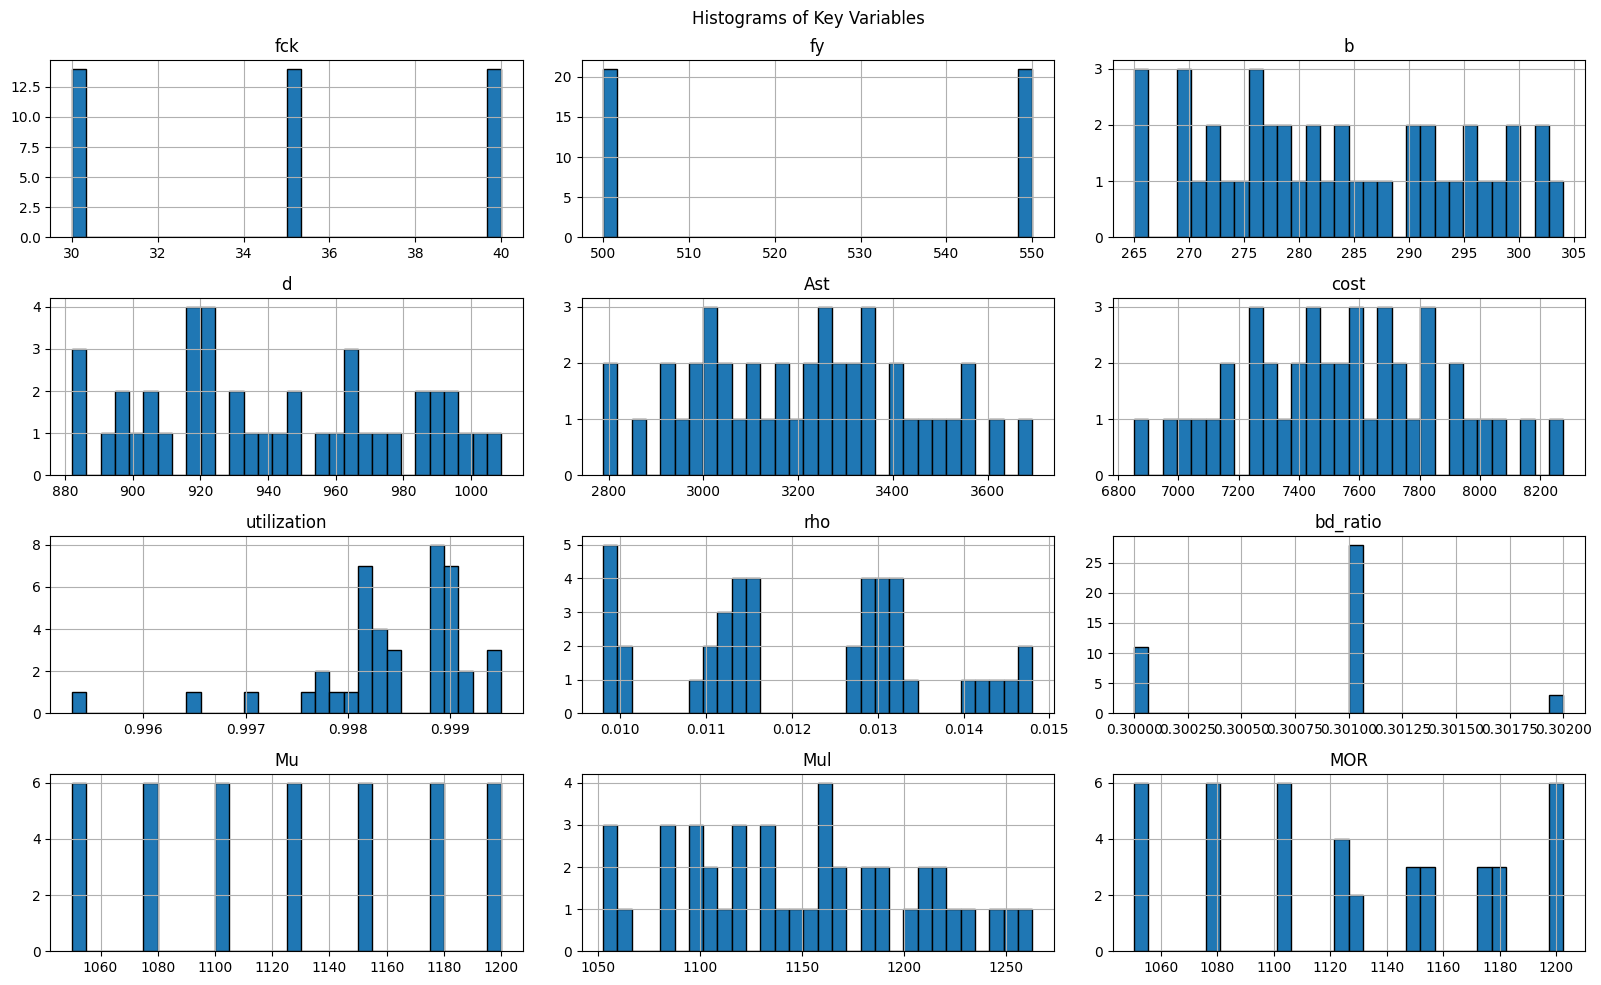

In [ ]:
# Distribution of numerical variables
numeric_cols = ['fck','fy', 'b', 'd', 'Ast',  'cost', 'utilization', 'rho', 'bd_ratio', 'Mu', 'Mul', 'MOR']
df[numeric_cols].hist(bins=30, figsize=(16, 10), edgecolor='black')
plt.suptitle("Histograms of Key Variables")
plt.tight_layout()
plt.show()

In [ ]:
df1 = df.drop(columns=['algorithm', 'is_valid', 'MOR', 'Mul', 'bd_ratio'], inplace=False)

In [ ]:
df1.describe()

,fck,fy,Mu,b,d,Ast,cost,utilization,rho
count,42.000000,42.000000,42.000000,42.000000,42.000000,42.00000,42.000000,42.000000,42.000000
mean,35.000000,525.000000,1125.000000,283.380952,942.166667,3213.67381,7542.879762,0.998414,0.012124
std,4.131969,25.303041,50.606083,11.320071,37.254508,226.88292,332.505601,0.000795,0.001478
min,30.000000,500.000000,1050.000000,265.000000,882.000000,2788.40000,6852.840000,0.995300,0.009800
25%,30.000000,500.000000,1075.000000,275.250000,916.250000,3033.82500,7300.007500,0.998100,0.011200
50%,35.000000,525.000000,1125.000000,282.000000,936.500000,3218.50000,7539.115000,0.998450,0.012150
75%,40.000000,550.000000,1175.000000,292.500000,971.750000,3355.37500,7784.050000,0.999000,0.013175
max,40.000000,550.000000,1200.000000,304.000000,1009.000000,3693.90000,8276.490000,0.999500,0.014800


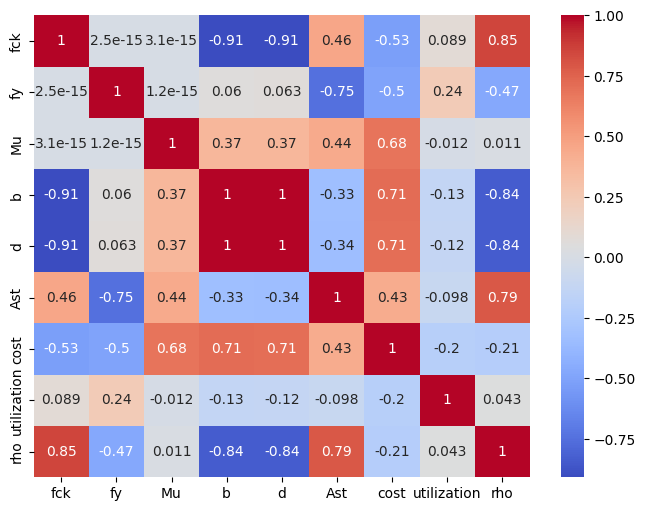

In [ ]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df1.corr(), annot=True, cmap='coolwarm')
plt.show()

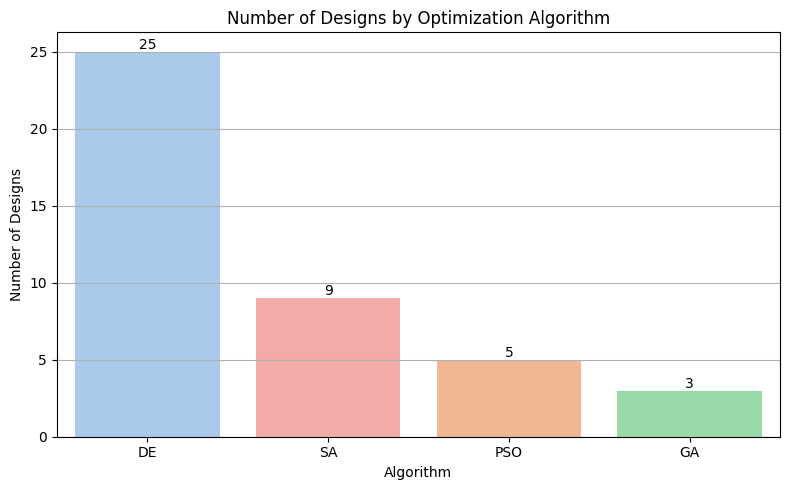

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='algorithm', hue='algorithm',
                   order=df['algorithm'].value_counts().index,
                   palette='pastel', legend=False)

# Optional: annotate counts
for p in ax.patches:
    ax.annotate(f'{round(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.title("Number of Designs by Optimization Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Number of Designs")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


#Detecting covariate shift

In [ ]:
first_data = pd.read_csv('ensemble_best_designs_1029.csv')
second_data = pd.read_csv('new_ensemble_best_designs.csv')
first_data = first_data[['Mu', 'cost']]
second_data = second_data[['Mu', 'cost']]

In [ ]:
first_data.head()

,Mu,cost
0,40,1380.85
1,60,1688.46
2,80,1946.00
3,100,2166.63
4,120,2381.65


In [ ]:
second_data.head()

,Mu,cost
0,1050,7560.66
1,1075,7685.25
2,1100,7802.70
3,1125,7917.94
4,1150,8045.26


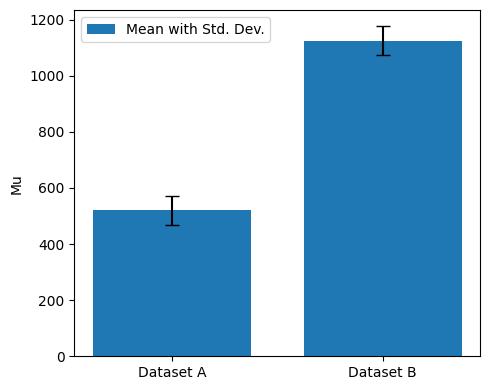

In [ ]:
labels = ['Dataset A', 'Dataset B']
means = [first_data['Mu'].mean(), second_data['Mu'].mean()]
stds = [second_data['Mu'].std(), second_data['Mu'].std()]

x = [0,0.4]
width = 0.3  # the width of the bars

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(x, means, width, yerr=stds, capsize=5, label='Mean with Std. Dev.')

# Add labels and title
# ax.set_xlabel('Datasets')
ax.set_ylabel('Mu')
# ax.set_title('Comparison of Cement Mean and Std Dev')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
# Show plot
plt.show()

##Kolmogorov-Smirnov (KS) test

The purpose of this test is to determine whether two independent samples are drawn from the same continuous distribution.

In [ ]:
from scipy.stats import ks_2samp
from statsmodels.stats.multitest import multipletests

# List to store p-values for multiple comparison correction
p_values = []
feature_names = first_data.columns

# Store results for easier inspection
results = []

for feature_name in feature_names:
    # Extract the feature values from both datasets
    feature_first_data = first_data[feature_name]
    feature_second_data = second_data[feature_name]

    # Perform the KS test
    statistic, p_value = ks_2samp(feature_first_data, feature_second_data)    #Performs the two-sample Kolmogorov-Smirnov test for goodness of fit.

    # Append the p-value for correction later
    p_values.append(p_value)

    # Store the result for later
    results.append({
        'Feature': feature_name,
        'Statistic': statistic,
        'p_value': p_value
    })

# Correct for multiple comparisons (Bonferroni correction or others)
corrected_p_values = multipletests(p_values, method='bonferroni')[1]

# Report results after correction
for i, result in enumerate(results):
    if corrected_p_values[i] < 0.05:
        print(f"Covariate shift detected for feature '{result['Feature']}'. "
              f"KS Statistic: {result['Statistic']}, Corrected p-value: {corrected_p_values[i]}")
    else:
        print(f"No significant covariate shift detected for feature '{result['Feature']}'. "
              f"KS Statistic: {result['Statistic']}, Corrected p-value: {corrected_p_values[i]}")


Covariate shift detected for feature 'Mu'. KS Statistic: 1.0, Corrected p-value: 7.117347121349592e-76
Covariate shift detected for feature 'cost'. KS Statistic: 0.8843537414965986, Corrected p-value: 7.381893285402136e-37


##Jensen-Shannon Divergence

The Jensen-Shannon Divergence (JSD) is a measure of similarity between two probability distributions, with values ranging between 0 and 1. It is a symmetrized and bounded version of the Kullback-Leibler (KL) divergence, making it easier to interpret and more suitable for detecting shifts.
Interpretation of JSD Values:

JSD = 0: This indicates that the two distributions are identical (no covariate shift).
JSD > 0: As JSD increases, the distributions become more dissimilar, signaling a greater degree of covariate shift.
JSD = 1: This indicates that the distributions are completely different, signifying a maximal covariate shift.

In [ ]:
from scipy.spatial.distance import jensenshannon
import numpy as np

def classify_jsd(jsd_value):
    if jsd_value < 0.1:
        return "Minimal difference"
    elif 0.1 <= jsd_value <= 0.25:
        return "Moderate difference"
    else:
        return "Large difference"

# Example: feature values from two datasets
feature_names = first_data.columns

for feature_name in feature_names:
  feature_first_data = first_data[feature_name]
  feature_second_data = second_data[feature_name]

  # Compute histograms to estimate the probability distributions
  hist1, bin_edges1 = np.histogram(feature_first_data, bins=30, density=True)
  hist2, bin_edges2 = np.histogram(feature_second_data, bins=30, density=True)

  # Calculate Jensen-Shannon Divergence
  js_divergence = jensenshannon(hist1, hist2)
  print(f"{feature_name} JSD: {js_divergence} ({classify_jsd(js_divergence)}) ")


Mu JSD: 0.5938196417095215 (Large difference) 
cost JSD: 0.2594751491079334 (Large difference) 
